# Analysing Pharmaceutical Sales Data

In this notebook, I use the daily sales data to compare the different drug categories. At the end, I also take a quick look at the hourly, weekly and monthly files.



In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")
daily = pd.read_csv(DATA / "salesdaily.csv", parse_dates=["datum"], dayfirst=False)
daily = daily.sort_values("datum").set_index("datum")
category_cols = [c for c in daily.columns if c not in ["datum", "Year", "Month", "Hour", "Weekday Name"]]
daily[category_cols].head()



,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
datum,,,,,,,,
2014-01-02,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0
2014-01-03,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0
2014-01-04,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0
2014-01-05,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0
2014-01-06,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0


## Inspect the data

The columns such as R03 and N02BE are drug categories. This file does not have individual medicine or brand names, so I can compare categories but not brands.



In [9]:
print("Shape:", daily.shape)
display(daily[category_cols].describe().T)
print("Date range:", daily.index.min().date(), "to", daily.index.max().date())
print("Missing values by category:")
display(daily[category_cols].isna().sum())



Shape: (2106, 12)


,count,mean,std,min,25%,50%,75%,max
M01AB,2106.0,5.033683,2.737579,0.0,3.00,4.99,6.670,17.340000
M01AE,2106.0,3.895830,2.133337,0.0,2.34,3.67,5.138,14.463000
N02BA,2106.0,3.880441,2.384010,0.0,2.00,3.50,5.200,16.000000
N02BE,2106.0,29.917095,15.590966,0.0,19.00,26.90,38.300,161.000000
N05B,2106.0,8.853627,5.605605,0.0,5.00,8.00,12.000,54.833333
N05C,2106.0,0.593522,1.092988,0.0,0.00,0.00,1.000,9.000000
R03,2106.0,5.512262,6.428736,0.0,1.00,4.00,8.000,45.000000
R06,2106.0,2.900198,2.415816,0.0,1.00,2.00,4.000,15.000000


Date range: 2014-01-02 to 2019-10-08
Missing values by category:


M01AB    0
M01AE    0
N02BA    0
N02BE    0
N05B     0
N05C     0
R03      0
R06      0
dtype: int64

## 1. Total sales by category



,Total sales quantity
N02BE,63005.402708
N05B,18645.737500
R03,11608.822917
M01AB,10600.937083
M01AE,8204.618646
N02BA,8172.209000
R06,6107.817500
N05C,1249.958333


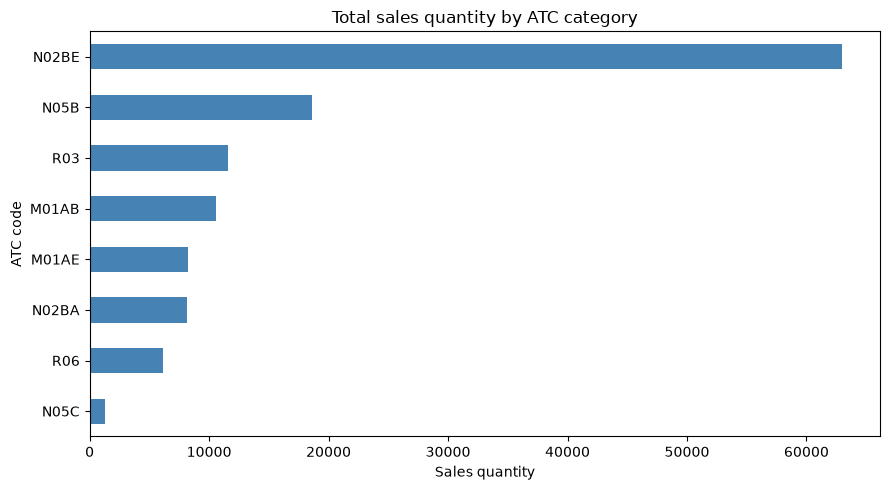

In [10]:
category_totals = daily[category_cols].sum().sort_values(ascending=False)
display(category_totals.to_frame("Total sales quantity"))
ax = category_totals.sort_values().plot.barh(figsize=(9, 5), color="steelblue")
ax.set(title="Total sales quantity by ATC category", xlabel="Sales quantity", ylabel="ATC code")
plt.tight_layout()



## 2. Which individual brands sold the most?

I cannot compare individual brands with this file. It only has category codes such as R03 and N02BE. I would need a dataset that includes product or brand names to answer this.



## 3. Top categories in the three requested months



In [11]:
months = [(2015, 1), (2016, 7), (2017, 9)]
for year, month in months:
    subset = daily.loc[(daily.index.year == year) & (daily.index.month == month), category_cols]
    totals = subset.sum().sort_values(ascending=False)
    print(f"{year}-{month:02d}: {len(subset)} daily records")
    display(totals.head(3).rename("Total monthly sales quantity").to_frame())



2015-01: 31 daily records


,Total monthly sales quantity
N02BE,1044.24
N05B,463.00
R03,177.25


2016-07: 31 daily records


,Total monthly sales quantity
N02BE,652.362000
N05B,240.000000
M01AB,194.528333


2017-09: 30 daily records


,Total monthly sales quantity
N02BE,863.75
N05B,223.00
R03,139.00


## 4. Which category had the most sales in 2017?

The file has category codes rather than individual drug names, so I compare the categories here.



In [12]:
sales_2017 = daily.loc[daily.index.year == 2017, category_cols].sum().sort_values(ascending=False)
display(sales_2017.to_frame("2017 sales quantity"))
print("Top category:", sales_2017.index[0], "—", sales_2017.iloc[0])



,2017 sales quantity
N02BE,9258.804833
N05B,2555.541667
R03,1893.614583
M01AB,1846.617083
M01AE,1387.298333
N02BA,1288.295833
R06,988.860000
N05C,180.333333


Top category: N02BE — 9258.80483333


## 5. Average daily sales by category



In [13]:
daily_average = daily[category_cols].mean().sort_values(ascending=False)
display(daily_average.to_frame("Average daily sales quantity"))
print("Highest average:", daily_average.index[0], "—", daily_average.iloc[0])



,Average daily sales quantity
N02BE,29.917095
N05B,8.853627
R03,5.512262
M01AB,5.033683
M01AE,3.895830
N02BA,3.880441
R06,2.900198
N05C,0.593522


Highest average: N02BE — 29.917095303105413


## 6. Does R03 sell more in some months?

I grouped R03 sales by calendar month. The average per day makes it easier to compare months; the chart also shows the total sales for each month.



,Mean daily quantity,Total quantity,Days observed
Jan,6.835980,1264.656250,185
Feb,6.896943,1165.583333,169
Mar,6.290323,1170.000000,186
Apr,5.771528,1038.875000,180
May,5.006944,931.291667,186
Jun,4.350000,783.000000,180
Jul,2.956989,550.000000,186
Aug,3.102151,577.000000,186
Sep,4.402315,792.416667,180
Oct,7.208589,1175.000000,163


Highest average daily sales month: Dec — 7.916129032258064


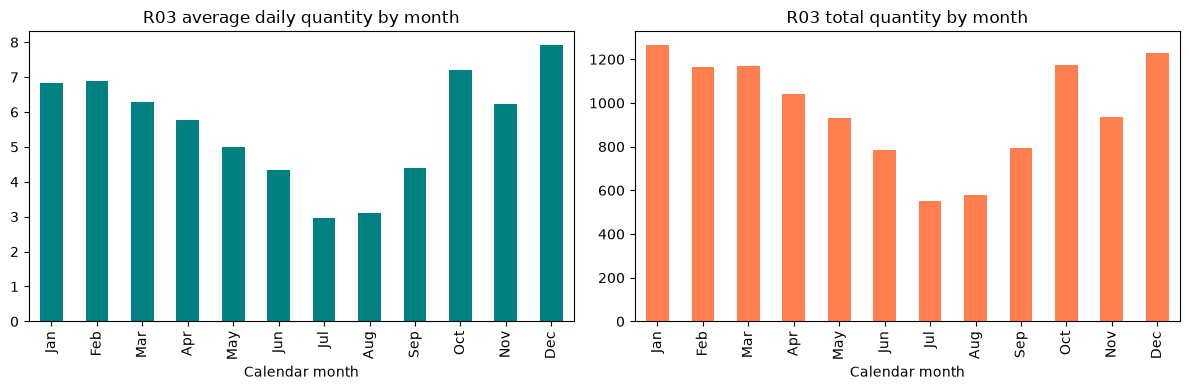

In [14]:
r03 = daily["R03"].dropna()
r03_by_month = r03.groupby(r03.index.month).agg(["mean", "sum", "count"])
r03_by_month.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
display(r03_by_month.rename(columns={"mean":"Mean daily quantity", "sum":"Total quantity", "count":"Days observed"}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
r03_by_month["mean"].plot.bar(ax=axes[0], color="teal", title="R03 average daily quantity by month")
r03_by_month["sum"].plot.bar(ax=axes[1], color="coral", title="R03 total quantity by month")
for ax in axes: ax.set_xlabel("Calendar month")
plt.tight_layout()
peak = r03_by_month["mean"].idxmax()
print("Highest average daily sales month:", peak, "—", r03_by_month.loc[peak, "mean"])



## A quick look at the other files

I used the daily file for the questions above. Here are a few rows from the hourly, weekly and monthly files.



In [15]:
for filename in ["saleshourly.csv", "salesweekly.csv", "salesmonthly.csv"]:
    frame = pd.read_csv(DATA / filename)
    print(filename, frame.shape, "columns:", list(frame.columns))
    display(frame.head(3))



saleshourly.csv (50532, 13) columns: ['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06', 'Year', 'Month', 'Hour', 'Weekday Name']


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014 8:00,0.0,0.67,0.4,2.0,0.0,0.0,0.0,1.0,2014,1,8,Thursday
1,1/2/2014 9:00,0.0,0.00,1.0,0.0,2.0,0.0,0.0,0.0,2014,1,9,Thursday
2,1/2/2014 10:00,0.0,0.00,0.0,3.0,2.0,0.0,0.0,0.0,2014,1,10,Thursday


salesweekly.csv (302, 9) columns: ['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,1/5/2014,14.00,11.67,21.3,185.95,41.0,0.0,32.0,7.0
1,1/12/2014,29.33,12.68,37.9,190.70,88.0,5.0,21.0,7.2
2,1/19/2014,30.67,26.34,45.9,218.40,80.0,8.0,29.0,12.0


salesmonthly.csv (70, 9) columns: ['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
0,2014-01-31,127.69,99.09,152.100,878.030,354.0,50.0,112.0,48.2
1,2014-02-28,133.32,126.05,177.000,1001.900,347.0,31.0,122.0,36.2
2,2014-03-31,137.44,92.95,147.655,779.275,232.0,20.0,112.0,85.4


“What I Learned”

### What I Learned

In this project, I used Pandas to explore the pharmaceutical sales data and compare sales across ATC categories. I used Matplotlib to create charts and see how respiratory drug (R03) sales changed across the months. This helped me practise working with data and presenting the results visually.
